# Associations and correlations between runs

With one row per run (`run_table()`), we can ask which quantities move together. This
notebook does that and then shows **three classic traps**:

1. Pearson vs Spearman: linear vs monotone association, and sensitivity to outliers.
2. **Confounding**: when a third variable (here: day versus night) drives both.
3. Uncertainty: with 68 runs, how sure are we of a correlation? (The bootstrap.)

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd()))  # notebooks/ (for pgdata)
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import pgdata
pgdata.style()
pd.set_option("display.precision", 3); pd.set_option("display.max_columns", 40); pd.set_option("display.width", 160)

In [2]:
rt = pgdata.run_table()
colors = pgdata.REGIME_COLORS
rt["Cy_norm_200"] = rt.cwic_200 / 1000 * rt.u_ref / rt.Q_g_s        # crosswind-integrated, normalised (m^-1)
rt["Cmax_norm_200"] = rt.peak_200 / 1000 * rt.u_ref / rt.Q_g_s      # peak, normalised (m^-2)
rt["spread_100"] = rt.sigma_y_m_100 / 100                           # sigma_y / x
nice = {"hour": "hour", "u_ref": "wind 2 m", "sigma_theta_source_10": "σθ", "dT_16_05": "ΔT 16–0.5 m",
        "Ri_b": "Ri", "wind_exp_p": "p (wind)", "u_star": "u*", "rad_net_radiation": "net rad.",
        "spread_100": "σy/x 100 m", "Cy_norm_200": "Cy·u/Q 200 m", "Cmax_norm_200": "Cmax·u/Q 200 m"}
X = rt[list(nice)].rename(columns=nice).astype(float)
X.describe().T[["count", "mean", "min", "max"]]

,count,mean,min,max
hour,68.0,13.684,4.167e-01,23.917
wind 2 m,68.0,4.713,4.400e-01,9.000
σθ,63.0,8.656,3.200e+00,25.600
ΔT 16–0.5 m,58.0,-0.147,-7.930e+00,6.380
Ri,66.0,-0.037,-7.554e-01,0.447
p (wind),68.0,0.232,1.125e-01,0.778
u*,68.0,0.338,6.406e-02,0.657
net rad.,67.0,0.004,-7.200e-03,0.015
σy/x 100 m,68.0,0.140,3.859e-02,0.482
Cy·u/Q 200 m,68.0,0.112,1.711e-02,0.328


## 1. The correlation matrix

**Spearman's ρ** is the Pearson correlation of the *ranks*. It captures any monotone
relationship and is robust to outliers and skew, which suits geophysical data spanning decades.
The colour scale is diverging: blue for negative, orange for positive, grey for nothing.

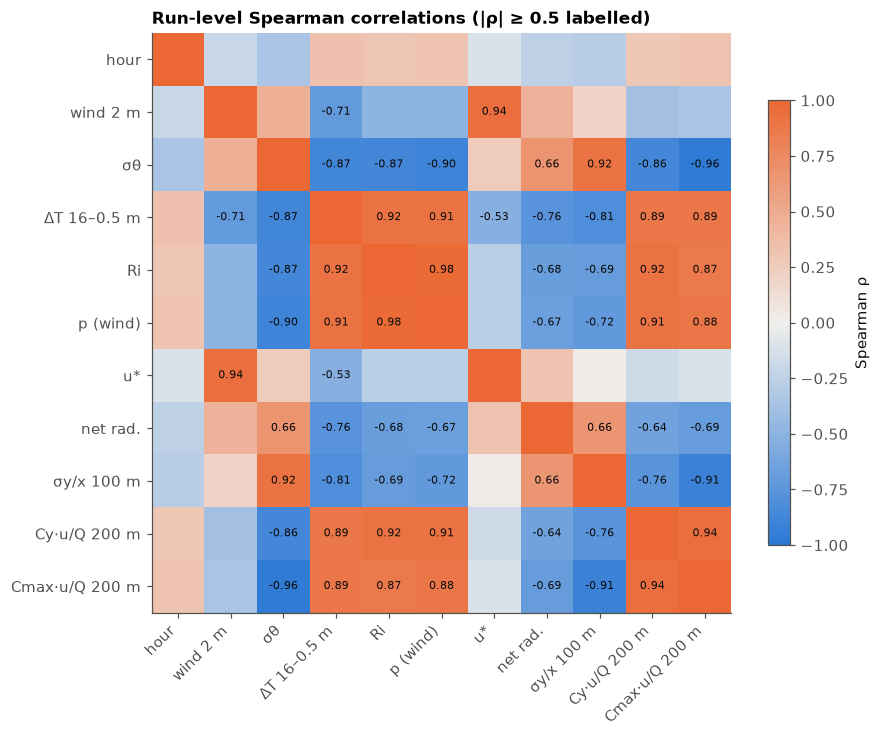

In [3]:
from matplotlib.colors import LinearSegmentedColormap
div = LinearSegmentedColormap.from_list("div", ["#2a78d6", "#f0efec", "#eb6834"])
rho = X.corr(method="spearman")
fig, ax = plt.subplots(figsize=(8.5, 7))
im = ax.imshow(rho, cmap=div, vmin=-1, vmax=1)
ax.set_xticks(range(len(rho)), rho.columns, rotation=45, ha="right"); ax.set_yticks(range(len(rho)), rho.index)
for i in range(len(rho)):
    for j in range(len(rho)):
        if i != j and abs(rho.iloc[i, j]) >= 0.5:
            ax.text(j, i, f"{rho.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7, color=pgdata.INK)
ax.grid(False); fig.colorbar(im, ax=ax, shrink=0.75, label="Spearman ρ")
ax.set_title("Run-level Spearman correlations (|ρ| ≥ 0.5 labelled)"); plt.show()

One axis dominates the matrix: **convective ↔ stable**. σ_θ, net radiation and plume spread
sit on one side. ΔT, Ri, the wind exponent p and the normalised concentrations sit on the
other. Wind speed and u* are only loosely tied to that axis, since they measure *mechanical*
turbulence.

The single best predictor of normalised concentration is **σ_θ** (ρ ≈ −0.96), a
one-instrument measurement. That matches Taylor's theory in notebook 06: the swing of the wind
sets the width of the plume, and the width sets the concentration.

The ten strongest pairs:

In [4]:
pairs = rho.where(np.triu(np.ones(rho.shape, bool), 1)).stack().rename("rho")
pairs.reindex(pairs.abs().sort_values(ascending=False).index).head(10).to_frame()

,,rho
Ri,p (wind),0.981
σθ,Cmax·u/Q 200 m,-0.964
Cy·u/Q 200 m,Cmax·u/Q 200 m,0.939
wind 2 m,u*,0.938
Ri,Cy·u/Q 200 m,0.920
ΔT 16–0.5 m,Ri,0.917
σθ,σy/x 100 m,0.916
ΔT 16–0.5 m,p (wind),0.914
p (wind),Cy·u/Q 200 m,0.914
σy/x 100 m,Cmax·u/Q 200 m,-0.911


## 2. Pearson vs Spearman

Pearson measures *linear* association. Normalised concentration varies over a factor of 100
and is strongly skewed, so a few stable runs dominate the Pearson coefficient. Taking logs
before Pearson, or using Spearman, gives a fairer summary.

In [5]:
comp = pd.DataFrame({
    "Pearson (raw)": X.corr()["Cmax·u/Q 200 m"],
    "Pearson (log conc.)": X.assign(**{"Cmax·u/Q 200 m": np.log10(X["Cmax·u/Q 200 m"])}).corr()["Cmax·u/Q 200 m"],
    "Spearman": rho["Cmax·u/Q 200 m"],
}).drop("Cmax·u/Q 200 m")
comp.sort_values("Spearman")

,Pearson (raw),Pearson (log conc.),Spearman
σθ,-0.637,-0.909,-0.964
σy/x 100 m,-0.568,-0.839,-0.911
net rad.,-0.550,-0.658,-0.689
wind 2 m,-0.504,-0.235,-0.344
u*,-0.317,-0.032,-0.115
hour,0.329,0.238,0.327
Ri,0.511,0.727,0.867
p (wind),0.741,0.624,0.878
ΔT 16–0.5 m,0.846,0.838,0.890
Cy·u/Q 200 m,0.856,0.851,0.939


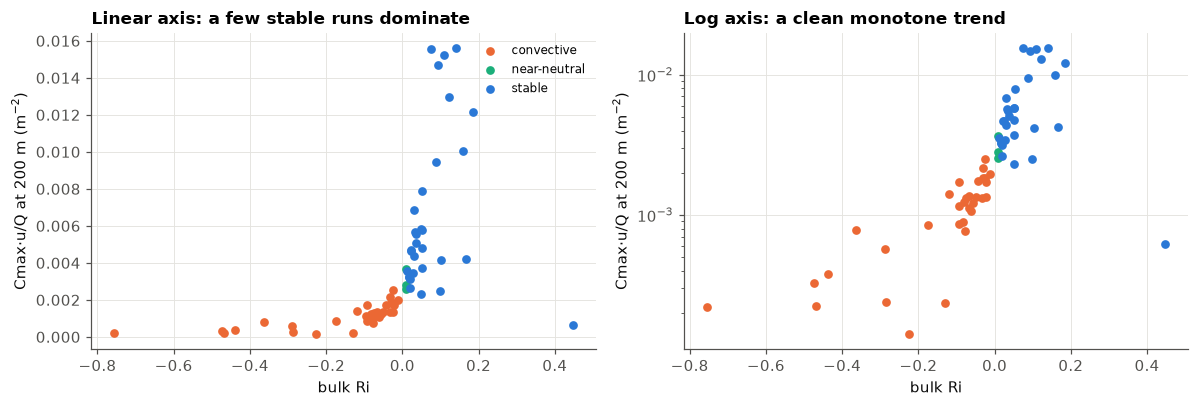

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, logy in zip(axes, [False, True]):
    for reg, g in rt.groupby("regime", observed=True):
        ax.scatter(g.Ri_b, g.Cmax_norm_200, color=colors[reg], s=22, label=reg)
    if logy: ax.set_yscale("log")
    ax.set_xlabel("bulk Ri"); ax.set_ylabel("Cmax·u/Q at 200 m (m$^{-2}$)")
axes[0].set_title("Linear axis: a few stable runs dominate"); axes[1].set_title("Log axis: a clean monotone trend")
axes[0].legend(fontsize=8); plt.tight_layout(); plt.show()

## 3. Confounding: the hidden third variable

Across all runs, *wind speed* and *normalised peak concentration* are **negatively**
correlated. Does stronger wind dilute the plume more than the 1/u we already divided out?

Look at the correlation *within* each regime before deciding:

,n,"Spearman ρ(u, Cmax·u/Q)"
group,,
all runs,68,-0.34
convective,32,0.76
stable,31,-0.46


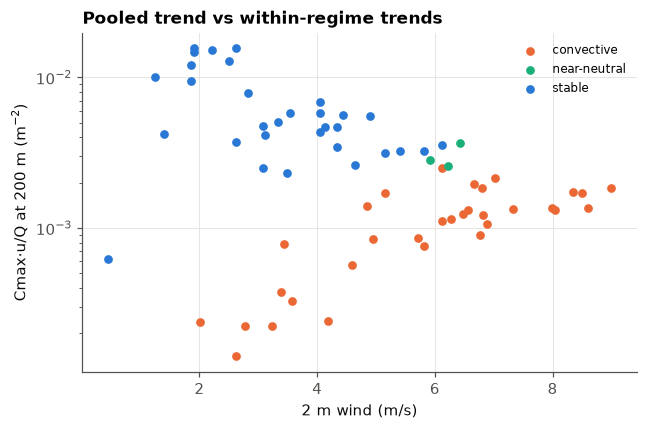

In [7]:
rows = []
for name, g in [("all runs", rt)] + list(rt.groupby("regime", observed=True)):
    g = g.dropna(subset=["u_ref", "Cmax_norm_200"])
    if len(g) >= 5:
        rows.append({"group": name, "n": len(g), "Spearman ρ(u, Cmax·u/Q)": g[["u_ref", "Cmax_norm_200"]].corr("spearman").iloc[0, 1]})
display(pd.DataFrame(rows).set_index("group").round(2))
fig, ax = plt.subplots(figsize=(6.5, 4))
for reg, g in rt.groupby("regime", observed=True):
    ax.scatter(g.u_ref, g.Cmax_norm_200, color=colors[reg], s=22, label=reg)
ax.set_yscale("log"); ax.set_xlabel("2 m wind (m/s)"); ax.set_ylabel("Cmax·u/Q at 200 m (m$^{-2}$)")
ax.set_title("Pooled trend vs within-regime trends"); ax.legend(fontsize=8); plt.show()

This is **Simpson's paradox**. Among convective runs the sign *flips*: a stronger wind goes with
a *higher* normalised concentration. That makes physical sense. A strong wind over a sunny
prairie means mechanical turbulence dominates buoyancy, so σ_θ is smaller and the plume is
narrower. The pooled negative trend mostly compares breezy afternoons with calm nights, and the
day/night difference (stability) acts as a **confounder**.

Rule of thumb: in field data, **stratify or condition on the regime before you interpret a
correlation**.

## 4. How sure are we? Bootstrapping a correlation

With 60-odd runs, any correlation carries real uncertainty. The **bootstrap** estimates it
without distributional assumptions: resample the runs with replacement, recompute the
correlation many times, and look at the spread.

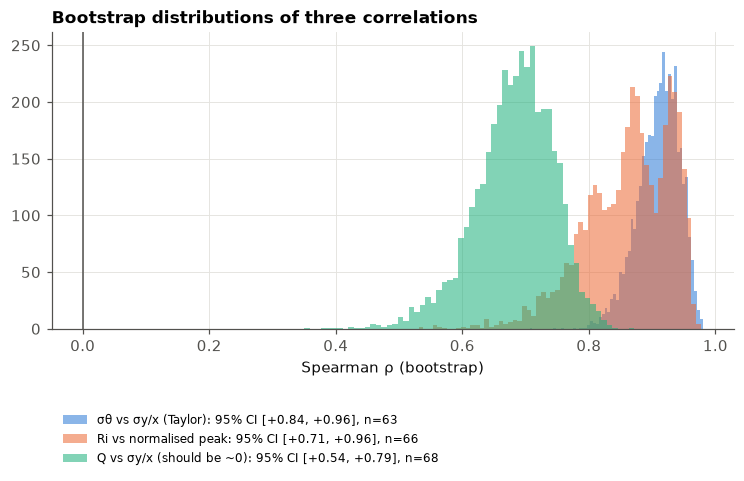

In [8]:
rng = np.random.default_rng(42)
def boot(a, b, n=4000):
    d = rt[[a, b]].dropna().to_numpy()
    out = np.empty(n)
    for i in range(n):
        s = d[rng.integers(0, len(d), len(d))]
        out[i] = pd.DataFrame(s).corr("spearman").iloc[0, 1]
    return len(d), out

tests = [("sigma_theta_source_10", "spread_100", "σθ vs σy/x (Taylor)"),
         ("Ri_b", "Cmax_norm_200", "Ri vs normalised peak"),
         ("Q_g_s", "spread_100", "Q vs σy/x (should be ~0)")]
fig, ax = plt.subplots(figsize=(8, 3.5))
for k, (a, b, lab) in enumerate(tests):
    n, bs = boot(a, b)
    lo, hi = np.percentile(bs, [2.5, 97.5])
    ax.hist(bs, bins=60, alpha=0.55, color=["#2a78d6", "#eb6834", "#1baf7a"][k], label=f"{lab}: 95% CI [{lo:+.2f}, {hi:+.2f}], n={n}")
ax.axvline(0, color=pgdata.MUTED, lw=1); ax.set_xlabel("Spearman ρ (bootstrap)"); ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(0, -0.25))
ax.set_title("Bootstrap distributions of three correlations"); plt.show()

The release rate Q is meant as a **negative control**. Physics says the *shape* of the plume
cannot depend on how much gas was released. Yet its interval sits well above zero. Why? The
experimenters chose the release rate *by time of day*: roughly 100 g/s by day and 40–50 g/s at
night, when less dilution was expected.

In [9]:
rt.groupby("day_night").Q_g_s.describe()[["count", "mean", "min", "max"]]

,count,mean,min,max
day_night,,,,
day,34.0,96.974,77.8,104.1
night,34.0,46.900,38.5,99.7


In [10]:
# condition on the regime and the Q-spread association largely goes away in the convective runs
rt.groupby("regime", observed=True)[["Q_g_s", "spread_100"]].corr("spearman").xs("Q_g_s", level=1)[["spread_100"]]     .rename(columns={"spread_100": "ρ(Q, σy/x)"}).join(rt.regime.value_counts().rename("n"))

,"ρ(Q, σy/x)",n
regime,,
convective,-0.092,32
near-neutral,-0.500,3
stable,0.432,31


**Takeaways**

- Spearman on run-level data, or Pearson on logs. Do not use Pearson on skewed concentrations.
- The correlation structure is dominated by one axis, *convective ↔ stable*. Almost every
  variable loads on it.
- Pooled correlations can be confounded. Stratify by regime before you interpret them.
- Bootstrap intervals are cheap. Put one on any correlation you quote.
- The experimenters' design choices (Q by time of day) create correlations that physics does
  not. A negative control catches them. Know how the data were collected.